# DeepConvNet for EEG Classification

**DeepConvNet** (Deep Convolutional Network) is a deep learning architecture specifically designed for EEG signal classification. It uses 4 convolutional blocks to learn hierarchical feature representations from raw EEG data.

**Key Features:**
- Deep architecture with 4 convolutional blocks
- Max pooling for dimensionality reduction
- Dropout for regularization
- Suitable for learning complex hierarchical patterns in EEG data

**Architecture:**
1. Temporal convolution (across time)
2. Spatial convolution (across channels) with max pooling
3. Three additional convolutional blocks with max pooling
4. Dense classification layer

**Reference:** Schirrmeister et al. (2017) - "Deep learning with convolutional neural networks for EEG decoding and visualization"

---

**Dataset:**
- 4 classes: Apple, Car, Flower, Human Face
- 14 EEG channels × 128 time points = 1792 features
- 5-fold stratified cross-validation
- Training on GPU with PyTorch

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import (accuracy_score, precision_score, recall_score, 
                             f1_score, confusion_matrix, classification_report)

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader

import warnings
warnings.filterwarnings('ignore')

# Set random seeds for reproducibility
np.random.seed(42)
torch.manual_seed(42)
if torch.cuda.is_available():
    torch.cuda.manual_seed(42)
    torch.cuda.manual_seed_all(42)

# Set plotting style
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette("husl")

print("✅ All libraries imported successfully!")

✅ All libraries imported successfully!


In [2]:
# Check if GPU is available
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

print("="*60)
print("GPU INFORMATION")
print("="*60)
print(f"PyTorch Version: {torch.__version__}")
print(f"CUDA Available: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"CUDA Version: {torch.version.cuda}")
    print(f"GPU Device: {torch.cuda.get_device_name(0)}")
    print(f"GPU Memory: {torch.cuda.get_device_properties(0).total_memory / 1024**3:.2f} GB")
    print(f"Current Device: {device}")
else:
    print(f"Current Device: {device} (CPU)")
print("="*60)

GPU INFORMATION
PyTorch Version: 2.5.1+cu121
CUDA Available: True
CUDA Version: 12.1
GPU Device: NVIDIA GeForce RTX 4060 Laptop GPU
GPU Memory: 8.00 GB
Current Device: cuda


In [ ]:
class DeepConvNet(nn.Module):
    """
    DeepConvNet for EEG classification.
    
    Deep architecture with 4 convolutional blocks for learning hierarchical features.
    Based on Schirrmeister et al. (2017).
    
    Architecture:
    1. Temporal convolution (1, 5) - captures temporal patterns
    2. Spatial convolution (Chans, 1) - captures spatial patterns across channels
    3. Max pooling (1, 2) + Dropout
    4. Conv Block 2: (1, 5) + Max pooling (1, 2) + Dropout
    5. Conv Block 3: (1, 5) + Max pooling (1, 2) + Dropout
    6. Conv Block 4: (1, 5) + Max pooling (1, 2) + Dropout
    7. Flatten + Dense layer for classification
    
    Parameters:
        nb_classes (int): Number of output classes
        Chans (int): Number of EEG channels
        Samples (int): Number of time samples
        dropoutRate (float): Dropout probability
    """
    def __init__(self, nb_classes=4, Chans=14, Samples=128, dropoutRate=0.5):
        super(DeepConvNet, self).__init__()
        
        self.nb_classes = nb_classes
        self.Chans = Chans
        self.Samples = Samples
        
        # Block 1: Temporal and Spatial Convolution
        self.conv1 = nn.Conv2d(1, 25, (1, 5), bias=True)
        self.conv2 = nn.Conv2d(25, 25, (Chans, 1), bias=True)
        self.bn1 = nn.BatchNorm2d(25, eps=1e-05, momentum=0.1)
        self.pool1 = nn.MaxPool2d((1, 2), stride=(1, 2))
        self.dropout1 = nn.Dropout(dropoutRate)
        
        # Block 2
        self.conv3 = nn.Conv2d(25, 50, (1, 5), bias=True)
        self.bn2 = nn.BatchNorm2d(50, eps=1e-05, momentum=0.1)
        self.pool2 = nn.MaxPool2d((1, 2), stride=(1, 2))
        self.dropout2 = nn.Dropout(dropoutRate)
        
        # Block 3
        self.conv4 = nn.Conv2d(50, 100, (1, 5), bias=True)
        self.bn3 = nn.BatchNorm2d(100, eps=1e-05, momentum=0.1)
        self.pool3 = nn.MaxPool2d((1, 2), stride=(1, 2))
        self.dropout3 = nn.Dropout(dropoutRate)
        
        # Block 4
        self.conv5 = nn.Conv2d(100, 200, (1, 5), bias=True)
        self.bn4 = nn.BatchNorm2d(200, eps=1e-05, momentum=0.1)
        self.pool4 = nn.MaxPool2d((1, 2), stride=(1, 2))
        self.dropout4 = nn.Dropout(dropoutRate)
        
        # Calculate output size after convolutions and pooling
        self._calculate_output_size()
        
        # Classification layer
        self.fc = nn.Linear(self.feature_size, nb_classes)
    
    def _calculate_output_size(self):
        """Calculate the output size after all conv and pooling layers."""
        # Create a dummy input to pass through the network in eval mode
        self.eval()
        with torch.no_grad():
            dummy_input = torch.zeros(1, 1, self.Chans, self.Samples)
            x = self.conv1(dummy_input)
            x = self.conv2(x)
            x = self.bn1(x)
            x = F.elu(x)
            x = self.pool1(x)
            
            x = self.conv3(x)
            x = self.bn2(x)
            x = F.elu(x)
            x = self.pool2(x)
            
            x = self.conv4(x)
            x = self.bn3(x)
            x = F.elu(x)
            x = self.pool3(x)
            
            x = self.conv5(x)
            x = self.bn4(x)
            x = F.elu(x)
            x = self.pool4(x)
            
            self.feature_size = x.numel()
        self.train()
    
    def forward(self, x):
        # Input shape: (batch, 1, Chans, Samples)
        
        # Block 1
        x = self.conv1(x)
        x = self.conv2(x)
        x = self.bn1(x)
        x = F.elu(x)
        x = self.pool1(x)
        x = self.dropout1(x)
        
        # Block 2
        x = self.conv3(x)
        x = self.bn2(x)
        x = F.elu(x)
        x = self.pool2(x)
        x = self.dropout2(x)
        
        # Block 3
        x = self.conv4(x)
        x = self.bn3(x)
        x = F.elu(x)
        x = self.pool3(x)
        x = self.dropout3(x)
        
        # Block 4
        x = self.conv5(x)
        x = self.bn4(x)
        x = F.elu(x)
        x = self.pool4(x)
        x = self.dropout4(x)
        
        # Flatten
        x = x.view(x.size(0), -1)
        
        # Classification
        x = self.fc(x)
        
        return x


# Test model initialization
print("Testing DeepConvNet architecture...")
model_test = DeepConvNet(nb_classes=4, Chans=14, Samples=128, dropoutRate=0.5)
test_input = torch.randn(2, 1, 14, 128)
test_output = model_test(test_input)
print(f"✅ DeepConvNet initialized successfully!")
print(f"   Input shape: {test_input.shape}")
print(f"   Output shape: {test_output.shape}")
print(f"   Number of parameters: {sum(p.numel() for p in model_test.parameters()):,}")
print(f"   Trainable parameters: {sum(p.numel() for p in model_test.parameters() if p.requires_grad):,}")
print(f"   Feature size before FC: {model_test.feature_size}")

Testing DeepConvNet architecture...
✅ DeepConvNet initialized successfully!
   Input shape: torch.Size([2, 1, 14, 128])
   Output shape: torch.Size([2, 4])
   Number of parameters: 144,479
   Trainable parameters: 144,479
   Feature size before FC: 800


In [5]:
def load_fold_data(fold_number):
    """
    Load training and testing data for a specific fold.
    
    Args:
        fold_number (int): Fold number (1-5)
    
    Returns:
        tuple: (X_train, y_train, X_test, y_test) all as numpy arrays
    """
    fold_dir = f'trainfold/fold_{fold_number}'
    
    # Load training data
    train_df = pd.read_csv(f'{fold_dir}/train.csv')
    X_train = train_df.iloc[:, :-1].values  # All columns except last
    y_train = train_df.iloc[:, -1].values   # Last column (label)
    
    # Load testing data
    test_df = pd.read_csv(f'{fold_dir}/test.csv')
    X_test = test_df.iloc[:, :-1].values
    y_test = test_df.iloc[:, -1].values
    
    return X_train, y_train, X_test, y_test


def prepare_data_for_deepconvnet(X, y, scaler=None, label_encoder=None, fit_transform=True):
    """
    Prepare data for DeepConvNet model.
    
    Args:
        X (np.array): Feature matrix (samples, 1792 features)
        y (np.array): Labels (samples,)
        scaler: StandardScaler object (if None, creates new one)
        label_encoder: LabelEncoder object (if None, creates new one)
        fit_transform (bool): If True, fit and transform. If False, only transform.
    
    Returns:
        tuple: (X_prepared, y_encoded, scaler, label_encoder)
    """
    # Initialize scaler and encoder if not provided
    if scaler is None:
        scaler = StandardScaler()
    if label_encoder is None:
        label_encoder = LabelEncoder()
    
    # Scale features
    if fit_transform:
        X_scaled = scaler.fit_transform(X)
        y_encoded = label_encoder.fit_transform(y)
    else:
        X_scaled = scaler.transform(X)
        y_encoded = label_encoder.transform(y)
    
    # Reshape to (samples, 1, 14, 128) for DeepConvNet
    # Original: 1792 features = 14 channels × 128 time points
    X_reshaped = X_scaled.reshape(-1, 14, 128)
    X_prepared = X_reshaped[:, np.newaxis, :, :]  # Add channel dimension
    
    return X_prepared, y_encoded, scaler, label_encoder


# Test data loading
print("Testing data loading and preparation...")
X_train_fold1, y_train_fold1, X_test_fold1, y_test_fold1 = load_fold_data(1)
print(f"✅ Data loaded successfully for Fold 1!")
print(f"   Training samples: {X_train_fold1.shape[0]}")
print(f"   Testing samples: {X_test_fold1.shape[0]}")
print(f"   Features: {X_train_fold1.shape[1]}")
print(f"   Unique classes in train: {np.unique(y_train_fold1)}")
print(f"   Unique classes in test: {np.unique(y_test_fold1)}")

# Test preprocessing
X_train_prep, y_train_prep, scaler_test, le_test = prepare_data_for_deepconvnet(
    X_train_fold1, y_train_fold1, fit_transform=True
)
X_test_prep, y_test_prep, _, _ = prepare_data_for_deepconvnet(
    X_test_fold1, y_test_fold1, scaler=scaler_test, label_encoder=le_test, fit_transform=False
)
print(f"\n✅ Data prepared for DeepConvNet!")
print(f"   X_train shape: {X_train_prep.shape}")
print(f"   X_test shape: {X_test_prep.shape}")
print(f"   y_train encoded: {np.unique(y_train_prep)}")
print(f"   y_test encoded: {np.unique(y_test_prep)}")

Testing data loading and preparation...
✅ Data loaded successfully for Fold 1!
   Training samples: 2889
   Testing samples: 723
   Features: 1792
   Unique classes in train: [1 2 3 4]
   Unique classes in test: [1 2 3 4]

✅ Data prepared for DeepConvNet!
   X_train shape: (2889, 1, 14, 128)
   X_test shape: (723, 1, 14, 128)
   y_train encoded: [0 1 2 3]
   y_test encoded: [0 1 2 3]
✅ Data loaded successfully for Fold 1!
   Training samples: 2889
   Testing samples: 723
   Features: 1792
   Unique classes in train: [1 2 3 4]
   Unique classes in test: [1 2 3 4]

✅ Data prepared for DeepConvNet!
   X_train shape: (2889, 1, 14, 128)
   X_test shape: (723, 1, 14, 128)
   y_train encoded: [0 1 2 3]
   y_test encoded: [0 1 2 3]


In [6]:
def train_epoch(model, train_loader, criterion, optimizer, device):
    """
    Train model for one epoch.
    
    Args:
        model: DeepConvNet model
        train_loader: DataLoader for training data
        criterion: Loss function
        optimizer: Optimizer
        device: Device to train on
    
    Returns:
        tuple: (average_loss, accuracy)
    """
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0
    
    for inputs, labels in train_loader:
        inputs, labels = inputs.to(device), labels.to(device)
        
        # Zero gradients
        optimizer.zero_grad()
        
        # Forward pass
        outputs = model(inputs)
        loss = criterion(outputs, labels)
        
        # Backward pass and optimize
        loss.backward()
        optimizer.step()
        
        # Statistics
        running_loss += loss.item() * inputs.size(0)
        _, predicted = torch.max(outputs, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()
    
    epoch_loss = running_loss / total
    epoch_acc = 100 * correct / total
    
    return epoch_loss, epoch_acc


def evaluate(model, test_loader, criterion, device):
    """
    Evaluate model on test data.
    
    Args:
        model: DeepConvNet model
        test_loader: DataLoader for test data
        criterion: Loss function
        device: Device to evaluate on
    
    Returns:
        tuple: (loss, accuracy, all_predictions, all_labels)
    """
    model.eval()
    running_loss = 0.0
    all_predictions = []
    all_labels = []
    
    with torch.no_grad():
        for inputs, labels in test_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            
            # Forward pass
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            
            # Statistics
            running_loss += loss.item() * inputs.size(0)
            _, predicted = torch.max(outputs, 1)
            
            all_predictions.extend(predicted.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())
    
    test_loss = running_loss / len(all_labels)
    test_acc = 100 * accuracy_score(all_labels, all_predictions)
    
    return test_loss, test_acc, all_predictions, all_labels


class EarlyStopping:
    """Early stopping to stop training when validation loss doesn't improve."""
    def __init__(self, patience=15, min_delta=0.0, verbose=True):
        self.patience = patience
        self.min_delta = min_delta
        self.verbose = verbose
        self.counter = 0
        self.best_loss = None
        self.early_stop = False
        self.best_model_state = None
        
    def __call__(self, val_loss, model):
        if self.best_loss is None:
            self.best_loss = val_loss
            self.best_model_state = model.state_dict().copy()
        elif val_loss > self.best_loss - self.min_delta:
            self.counter += 1
            if self.verbose:
                print(f'   EarlyStopping counter: {self.counter}/{self.patience}')
            if self.counter >= self.patience:
                self.early_stop = True
        else:
            if self.verbose:
                print(f'   Validation loss improved ({self.best_loss:.6f} → {val_loss:.6f})')
            self.best_loss = val_loss
            self.best_model_state = model.state_dict().copy()
            self.counter = 0
        
        return self.early_stop

print("✅ Training and evaluation functions defined!")

✅ Training and evaluation functions defined!


In [7]:
# Hyperparameters
BATCH_SIZE = 32
LEARNING_RATE = 0.001
NUM_EPOCHS = 100
PATIENCE = 15
NUM_FOLDS = 5
DROPOUT_RATE = 0.5

# Storage for results
fold_results = []
all_confusion_matrices = []
training_histories = []

# Class names
class_names = ['Apple', 'Car', 'Flower', 'Human Face']

print("=" * 80)
print("STARTING 5-FOLD CROSS-VALIDATION FOR DeepConvNet")
print("=" * 80)
print(f"Batch Size: {BATCH_SIZE}")
print(f"Learning Rate: {LEARNING_RATE}")
print(f"Max Epochs: {NUM_EPOCHS}")
print(f"Early Stopping Patience: {PATIENCE}")
print(f"Dropout Rate: {DROPOUT_RATE}")
print(f"Device: {device}")
print("=" * 80)

# Training loop for each fold
for fold in range(1, NUM_FOLDS + 1):
    print(f"\n{'='*80}")
    print(f"FOLD {fold}/{NUM_FOLDS}")
    print(f"{'='*80}")
    
    # Load data for this fold
    X_train, y_train, X_test, y_test = load_fold_data(fold)
    print(f"Loaded data - Train: {X_train.shape[0]} samples, Test: {X_test.shape[0]} samples")
    
    # Prepare data
    X_train_prep, y_train_prep, scaler, label_encoder = prepare_data_for_deepconvnet(
        X_train, y_train, fit_transform=True
    )
    X_test_prep, y_test_prep, _, _ = prepare_data_for_deepconvnet(
        X_test, y_test, scaler=scaler, label_encoder=label_encoder, fit_transform=False
    )
    
    # Convert to PyTorch tensors
    X_train_tensor = torch.FloatTensor(X_train_prep)
    y_train_tensor = torch.LongTensor(y_train_prep)
    X_test_tensor = torch.FloatTensor(X_test_prep)
    y_test_tensor = torch.LongTensor(y_test_prep)
    
    # Create datasets and dataloaders
    train_dataset = torch.utils.data.TensorDataset(X_train_tensor, y_train_tensor)
    test_dataset = torch.utils.data.TensorDataset(X_test_tensor, y_test_tensor)
    
    train_loader = torch.utils.data.DataLoader(
        train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=0
    )
    test_loader = torch.utils.data.DataLoader(
        test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0
    )
    
    # Initialize model
    model = DeepConvNet(nb_classes=4, Chans=14, Samples=128, dropoutRate=DROPOUT_RATE).to(device)
    print(f"Model initialized with {sum(p.numel() for p in model.parameters()):,} parameters")
    
    # Loss and optimizer
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE)
    scheduler = optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode='min', factor=0.5, patience=5, verbose=True
    )
    
    # Early stopping
    early_stopping = EarlyStopping(patience=PATIENCE, verbose=True)
    
    # Training history
    history = {
        'train_loss': [], 'train_acc': [],
        'test_loss': [], 'test_acc': []
    }
    
    # Training loop
    print(f"\nStarting training...")
    best_test_acc = 0.0
    
    for epoch in range(NUM_EPOCHS):
        # Train
        train_loss, train_acc = train_epoch(model, train_loader, criterion, optimizer, device)
        
        # Evaluate
        test_loss, test_acc, _, _ = evaluate(model, test_loader, criterion, device)
        
        # Update scheduler
        scheduler.step(test_loss)
        
        # Save history
        history['train_loss'].append(train_loss)
        history['train_acc'].append(train_acc)
        history['test_loss'].append(test_loss)
        history['test_acc'].append(test_acc)
        
        # Print progress
        if (epoch + 1) % 10 == 0 or epoch == 0:
            print(f"Epoch [{epoch+1}/{NUM_EPOCHS}] - "
                  f"Train Loss: {train_loss:.4f}, Train Acc: {train_acc:.2f}% | "
                  f"Test Loss: {test_loss:.4f}, Test Acc: {test_acc:.2f}%")
        
        # Track best accuracy
        if test_acc > best_test_acc:
            best_test_acc = test_acc
        
        # Early stopping check
        if early_stopping(test_loss, model):
            print(f"\n⚠️  Early stopping triggered at epoch {epoch+1}")
            break
    
    # Load best model
    model.load_state_dict(early_stopping.best_model_state)
    
    # Final evaluation
    print(f"\nFinal evaluation on test set...")
    test_loss, test_acc, y_pred, y_true = evaluate(model, test_loader, criterion, device)
    
    # Calculate detailed metrics
    accuracy = accuracy_score(y_true, y_pred)
    precision_macro = precision_score(y_true, y_pred, average='macro')
    precision_weighted = precision_score(y_true, y_pred, average='weighted')
    recall_macro = recall_score(y_true, y_pred, average='macro')
    recall_weighted = recall_score(y_true, y_pred, average='weighted')
    f1_macro = f1_score(y_true, y_pred, average='macro')
    f1_weighted = f1_score(y_true, y_pred, average='weighted')
    
    # Confusion matrix
    cm = confusion_matrix(y_true, y_pred)
    
    # Store results
    fold_result = {
        'Fold': fold,
        'Accuracy': accuracy,
        'Precision_Macro': precision_macro,
        'Precision_Weighted': precision_weighted,
        'Recall_Macro': recall_macro,
        'Recall_Weighted': recall_weighted,
        'F1_Macro': f1_macro,
        'F1_Weighted': f1_weighted,
        'Best_Epoch': epoch + 1,
        'Final_Train_Loss': history['train_loss'][-1],
        'Final_Train_Acc': history['train_acc'][-1],
        'Final_Test_Loss': history['test_loss'][-1],
        'Final_Test_Acc': history['test_acc'][-1]
    }
    
    fold_results.append(fold_result)
    all_confusion_matrices.append(cm)
    training_histories.append(history)
    
    print(f"\n{'='*80}")
    print(f"FOLD {fold} RESULTS:")
    print(f"{'='*80}")
    print(f"Accuracy:           {accuracy:.4f}")
    print(f"Precision (Macro):  {precision_macro:.4f}")
    print(f"Precision (Weighted): {precision_weighted:.4f}")
    print(f"Recall (Macro):     {recall_macro:.4f}")
    print(f"Recall (Weighted):  {recall_weighted:.4f}")
    print(f"F1-Score (Macro):   {f1_macro:.4f}")
    print(f"F1-Score (Weighted): {f1_weighted:.4f}")
    print(f"Best Epoch:         {epoch + 1}")
    print(f"{'='*80}")
    
    # Clean up
    del model, optimizer, scheduler, train_loader, test_loader
    torch.cuda.empty_cache() if torch.cuda.is_available() else None

print(f"\n{'='*80}")
print("ALL FOLDS COMPLETED!")
print(f"{'='*80}")

STARTING 5-FOLD CROSS-VALIDATION FOR DeepConvNet
Batch Size: 32
Learning Rate: 0.001
Max Epochs: 100
Early Stopping Patience: 15
Dropout Rate: 0.5
Device: cuda

FOLD 1/5
Loaded data - Train: 2889 samples, Test: 723 samples
Loaded data - Train: 2889 samples, Test: 723 samples
Model initialized with 144,479 parameters
Model initialized with 144,479 parameters

Starting training...

Starting training...
Epoch [1/100] - Train Loss: 1.5671, Train Acc: 26.27% | Test Loss: 1.3938, Test Acc: 28.91%
Epoch [1/100] - Train Loss: 1.5671, Train Acc: 26.27% | Test Loss: 1.3938, Test Acc: 28.91%
   Validation loss improved (1.393756 → 1.389218)
   Validation loss improved (1.393756 → 1.389218)
   Validation loss improved (1.389218 → 1.378698)
   Validation loss improved (1.389218 → 1.378698)
   EarlyStopping counter: 1/15
   EarlyStopping counter: 1/15
   Validation loss improved (1.378698 → 1.378542)
   Validation loss improved (1.378698 → 1.378542)
   EarlyStopping counter: 1/15
   EarlyStopping co

In [8]:
# Create results DataFrame
results_df = pd.DataFrame(fold_results)

# Calculate mean and std for each metric
summary_stats = {
    'Metric': ['Accuracy', 'Precision_Macro', 'Precision_Weighted', 
               'Recall_Macro', 'Recall_Weighted', 'F1_Macro', 'F1_Weighted'],
    'Mean': [
        results_df['Accuracy'].mean(),
        results_df['Precision_Macro'].mean(),
        results_df['Precision_Weighted'].mean(),
        results_df['Recall_Macro'].mean(),
        results_df['Recall_Weighted'].mean(),
        results_df['F1_Macro'].mean(),
        results_df['F1_Weighted'].mean()
    ],
    'Std': [
        results_df['Accuracy'].std(),
        results_df['Precision_Macro'].std(),
        results_df['Precision_Weighted'].std(),
        results_df['Recall_Macro'].std(),
        results_df['Recall_Weighted'].std(),
        results_df['F1_Macro'].std(),
        results_df['F1_Weighted'].std()
    ]
}

summary_df = pd.DataFrame(summary_stats)

# Display results
print("\n" + "="*80)
print("PERFORMANCE SUMMARY ACROSS ALL FOLDS")
print("="*80)
print("\nPer-Fold Results:")
print(results_df.to_string(index=False))
print("\n" + "-"*80)
print("\nSummary Statistics:")
print(summary_df.to_string(index=False))
print("="*80)

# Save results
results_df.to_csv('deepconvnet_fold_details.csv', index=False)
summary_df.to_csv('deepconvnet_results_summary.csv', index=False)
print("\n✅ Results saved to:")
print("   - deepconvnet_fold_details.csv")
print("   - deepconvnet_results_summary.csv")


PERFORMANCE SUMMARY ACROSS ALL FOLDS

Per-Fold Results:
 Fold  Accuracy  Precision_Macro  Precision_Weighted  Recall_Macro  Recall_Weighted  F1_Macro  F1_Weighted  Best_Epoch  Final_Train_Loss  Final_Train_Acc  Final_Test_Loss  Final_Test_Acc
    1  0.785615         0.787123            0.793558      0.784205         0.785615  0.779962     0.783881         100          0.515309        78.539287         0.502870       78.561549
    2  0.777317         0.768685            0.782383      0.771343         0.777317  0.768442     0.778299         100          0.513196        79.162340         0.523791       77.731674
    3  0.788089         0.791618            0.795383      0.778217         0.788089  0.779954     0.786461         100          0.550720        77.474048         0.510928       78.808864
    4  0.743767         0.753474            0.763638      0.738554         0.743767  0.725941     0.734643          74          0.569572        76.712803         0.641241       74.376731
    5  0

## 7.5. Overfitting Analysis

In [9]:
# Analyze overfitting for each fold
print("\n" + "="*80)
print("OVERFITTING ANALYSIS")
print("="*80)

overfitting_metrics = []

for fold_idx, (fold_result, history) in enumerate(zip(fold_results, training_histories)):
    fold_num = fold_idx + 1
    
    # Calculate overfitting indicators
    final_train_acc = fold_result['Final_Train_Acc']
    final_test_acc = fold_result['Final_Test_Acc']
    final_train_loss = fold_result['Final_Train_Loss']
    final_test_loss = fold_result['Final_Test_Loss']
    
    # Overfitting gap
    accuracy_gap = final_train_acc - final_test_acc
    loss_gap = final_test_loss - final_train_loss
    
    # Calculate if loss was increasing
    best_epoch = fold_result['Best_Epoch']
    if best_epoch < len(history['test_loss']):
        # Test loss increased after best epoch (sign of overfitting)
        test_loss_increased = history['test_loss'][-1] > history['test_loss'][best_epoch - 1]
    else:
        test_loss_increased = False
    
    # Overfitting severity
    if accuracy_gap > 20:
        severity = "🔴 SEVERE"
    elif accuracy_gap > 10:
        severity = "🟡 MODERATE"
    elif accuracy_gap > 5:
        severity = "🟢 MILD"
    else:
        severity = "✅ GOOD"
    
    overfitting_metrics.append({
        'Fold': fold_num,
        'Train_Acc': final_train_acc,
        'Test_Acc': final_test_acc,
        'Acc_Gap': accuracy_gap,
        'Train_Loss': final_train_loss,
        'Test_Loss': final_test_loss,
        'Loss_Gap': loss_gap,
        'Best_Epoch': best_epoch,
        'Total_Epochs': len(history['train_loss']),
        'Severity': severity
    })
    
    print(f"\nFold {fold_num}:")
    print(f"  Train Accuracy:     {final_train_acc:.2f}%")
    print(f"  Test Accuracy:      {final_test_acc:.2f}%")
    print(f"  Accuracy Gap:       {accuracy_gap:.2f}% {severity}")
    print(f"  Train Loss:         {final_train_loss:.4f}")
    print(f"  Test Loss:          {final_test_loss:.4f}")
    print(f"  Loss Gap:           {loss_gap:.4f}")
    print(f"  Best Epoch:         {best_epoch}/{len(history['train_loss'])}")

# Create DataFrame
overfitting_df = pd.DataFrame(overfitting_metrics)

# Calculate average overfitting
avg_acc_gap = overfitting_df['Acc_Gap'].mean()
avg_loss_gap = overfitting_df['Loss_Gap'].mean()

print("\n" + "="*80)
print("SUMMARY:")
print("="*80)
print(f"Average Accuracy Gap:  {avg_acc_gap:.2f}%")
print(f"Average Loss Gap:      {avg_loss_gap:.4f}")
print(f"Average Train Acc:     {overfitting_df['Train_Acc'].mean():.2f}%")
print(f"Average Test Acc:      {overfitting_df['Test_Acc'].mean():.2f}%")

if avg_acc_gap > 20:
    print("\n⚠️  SEVERE OVERFITTING DETECTED!")
    print("Recommendations:")
    print("  1. Increase dropout rate (current: 0.5 → try 0.6-0.7)")
    print("  2. Add L2 regularization (weight_decay in optimizer)")
    print("  3. Use data augmentation")
    print("  4. Reduce model complexity")
    print("  5. Collect more training data")
elif avg_acc_gap > 10:
    print("\n⚠️  MODERATE OVERFITTING DETECTED!")
    print("Recommendations:")
    print("  1. Increase dropout rate slightly (current: 0.5 → try 0.55-0.6)")
    print("  2. Add mild L2 regularization")
    print("  3. Consider data augmentation")
elif avg_acc_gap > 5:
    print("\n✅ MILD OVERFITTING - This is acceptable!")
    print("Some overfitting is normal and doesn't significantly impact performance.")
else:
    print("\n✅ EXCELLENT! No significant overfitting detected!")

# Save overfitting analysis
overfitting_df.to_csv('deepconvnet_overfitting_analysis.csv', index=False)
print(f"\n✅ Overfitting analysis saved to: deepconvnet_overfitting_analysis.csv")
print("="*80)


OVERFITTING ANALYSIS

Fold 1:
  Train Accuracy:     78.54%
  Test Accuracy:      78.56%
  Accuracy Gap:       -0.02% ✅ GOOD
  Train Loss:         0.5153
  Test Loss:          0.5029
  Loss Gap:           -0.0124
  Best Epoch:         100/100

Fold 2:
  Train Accuracy:     79.16%
  Test Accuracy:      77.73%
  Accuracy Gap:       1.43% ✅ GOOD
  Train Loss:         0.5132
  Test Loss:          0.5238
  Loss Gap:           0.0106
  Best Epoch:         100/100

Fold 3:
  Train Accuracy:     77.47%
  Test Accuracy:      78.81%
  Accuracy Gap:       -1.33% ✅ GOOD
  Train Loss:         0.5507
  Test Loss:          0.5109
  Loss Gap:           -0.0398
  Best Epoch:         100/100

Fold 4:
  Train Accuracy:     76.71%
  Test Accuracy:      74.38%
  Accuracy Gap:       2.34% ✅ GOOD
  Train Loss:         0.5696
  Test Loss:          0.6412
  Loss Gap:           0.0717
  Best Epoch:         74/74

Fold 5:
  Train Accuracy:     76.71%
  Test Accuracy:      75.76%
  Accuracy Gap:       0.95% ✅ GOO

## 7.6. Visualize Overfitting

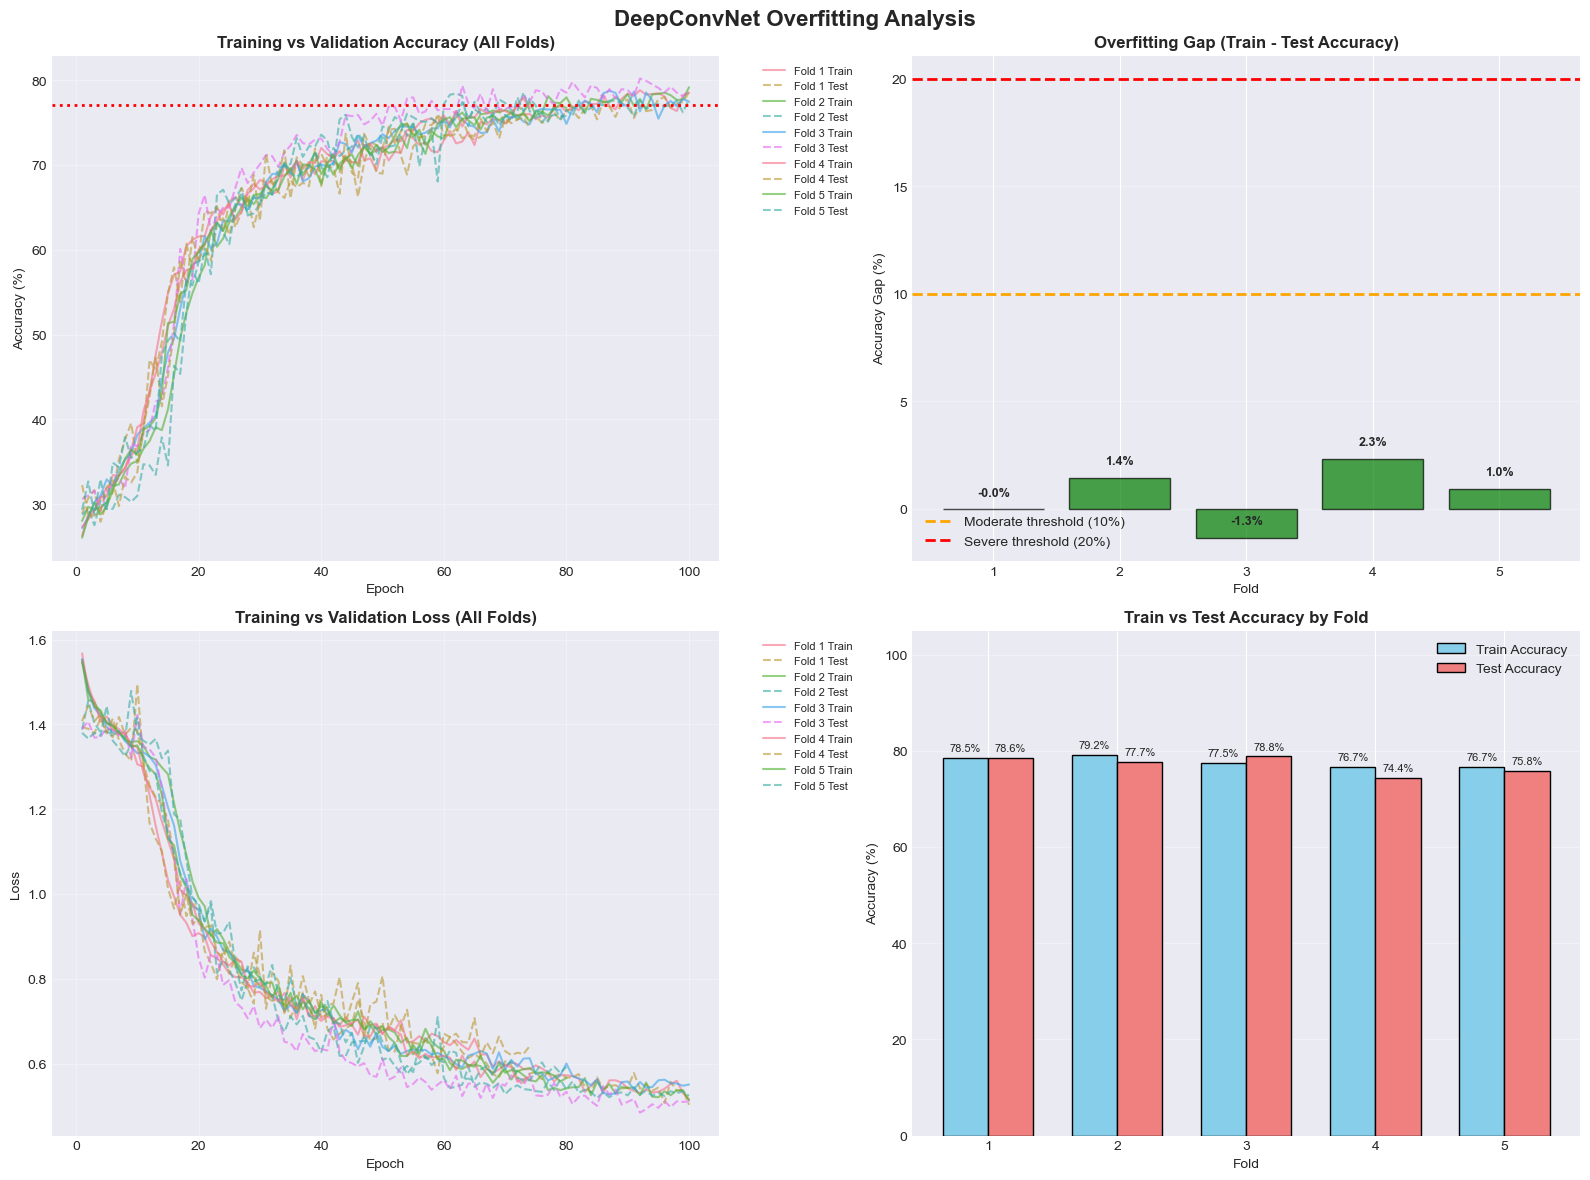

✅ Overfitting visualization saved to: deepconvnet_overfitting_analysis.png


In [10]:
# Visualize overfitting patterns
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
fig.suptitle('DeepConvNet Overfitting Analysis', fontsize=16, fontweight='bold')

# Plot 1: Train vs Test Accuracy for each fold
for fold_idx, history in enumerate(training_histories):
    epochs = range(1, len(history['train_acc']) + 1)
    axes[0, 0].plot(epochs, history['train_acc'], 
                    label=f'Fold {fold_idx+1} Train', linestyle='-', alpha=0.6)
    axes[0, 0].plot(epochs, history['test_acc'], 
                    label=f'Fold {fold_idx+1} Test', linestyle='--', alpha=0.6)

axes[0, 0].set_title('Training vs Validation Accuracy (All Folds)', fontsize=12, fontweight='bold')
axes[0, 0].set_xlabel('Epoch')
axes[0, 0].set_ylabel('Accuracy (%)')
axes[0, 0].legend(bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=8)
axes[0, 0].grid(True, alpha=0.3)
axes[0, 0].axhline(y=overfitting_df['Test_Acc'].mean(), color='red', 
                   linestyle=':', label='Avg Test Acc', linewidth=2)

# Plot 2: Accuracy Gap per fold
folds = overfitting_df['Fold'].values
acc_gaps = overfitting_df['Acc_Gap'].values
colors = ['red' if gap > 20 else 'orange' if gap > 10 else 'yellow' if gap > 5 else 'green' 
          for gap in acc_gaps]

axes[0, 1].bar(folds, acc_gaps, color=colors, edgecolor='black', alpha=0.7)
axes[0, 1].axhline(y=10, color='orange', linestyle='--', label='Moderate threshold (10%)', linewidth=2)
axes[0, 1].axhline(y=20, color='red', linestyle='--', label='Severe threshold (20%)', linewidth=2)
axes[0, 1].set_title('Overfitting Gap (Train - Test Accuracy)', fontsize=12, fontweight='bold')
axes[0, 1].set_xlabel('Fold')
axes[0, 1].set_ylabel('Accuracy Gap (%)')
axes[0, 1].set_xticks(folds)
axes[0, 1].legend()
axes[0, 1].grid(True, alpha=0.3, axis='y')

# Add value labels
for i, (fold, gap) in enumerate(zip(folds, acc_gaps)):
    axes[0, 1].text(fold, gap + 0.5, f'{gap:.1f}%', ha='center', va='bottom', fontsize=9, fontweight='bold')

# Plot 3: Train vs Test Loss
for fold_idx, history in enumerate(training_histories):
    epochs = range(1, len(history['train_loss']) + 1)
    axes[1, 0].plot(epochs, history['train_loss'], 
                    label=f'Fold {fold_idx+1} Train', linestyle='-', alpha=0.6)
    axes[1, 0].plot(epochs, history['test_loss'], 
                    label=f'Fold {fold_idx+1} Test', linestyle='--', alpha=0.6)

axes[1, 0].set_title('Training vs Validation Loss (All Folds)', fontsize=12, fontweight='bold')
axes[1, 0].set_xlabel('Epoch')
axes[1, 0].set_ylabel('Loss')
axes[1, 0].legend(bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=8)
axes[1, 0].grid(True, alpha=0.3)

# Plot 4: Train Acc vs Test Acc comparison
train_accs = overfitting_df['Train_Acc'].values
test_accs = overfitting_df['Test_Acc'].values

x = np.arange(len(folds))
width = 0.35

bars1 = axes[1, 1].bar(x - width/2, train_accs, width, label='Train Accuracy', 
                       color='skyblue', edgecolor='black')
bars2 = axes[1, 1].bar(x + width/2, test_accs, width, label='Test Accuracy', 
                       color='lightcoral', edgecolor='black')

axes[1, 1].set_title('Train vs Test Accuracy by Fold', fontsize=12, fontweight='bold')
axes[1, 1].set_xlabel('Fold')
axes[1, 1].set_ylabel('Accuracy (%)')
axes[1, 1].set_xticks(x)
axes[1, 1].set_xticklabels(folds)
axes[1, 1].legend()
axes[1, 1].grid(True, alpha=0.3, axis='y')
axes[1, 1].set_ylim([0, 105])

# Add value labels on bars
for bars in [bars1, bars2]:
    for bar in bars:
        height = bar.get_height()
        axes[1, 1].text(bar.get_x() + bar.get_width()/2., height + 1,
                       f'{height:.1f}%', ha='center', va='bottom', fontsize=8)

plt.tight_layout()
plt.savefig('deepconvnet_overfitting_analysis.png', dpi=300, bbox_inches='tight')
plt.show()

print("✅ Overfitting visualization saved to: deepconvnet_overfitting_analysis.png")

## 7.7. Per-Class Accuracy Analysis

In [14]:
# Calculate per-class accuracy from confusion matrices
print("\n" + "="*80)
print("PER-CLASS ACCURACY ANALYSIS")
print("="*80)

# Calculate per-class accuracy for each fold
per_class_accuracies = []

for fold_idx, cm in enumerate(all_confusion_matrices):
    fold_num = fold_idx + 1
    
    # Calculate accuracy for each class
    class_accuracies = []
    for i, class_name in enumerate(class_names):
        # Accuracy = correctly predicted / total samples of this class
        correct = cm[i, i]
        total = cm[i, :].sum()
        accuracy = 100 * correct / total if total > 0 else 0
        class_accuracies.append(accuracy)
    
    per_class_accuracies.append({
        'Fold': fold_num,
        'Apple': class_accuracies[0],
        'Car': class_accuracies[1],
        'Flower': class_accuracies[2],
        'Human_Face': class_accuracies[3],
        'Average': np.mean(class_accuracies)
    })
    
    print(f"\nFold {fold_num}:")
    for i, class_name in enumerate(class_names):
        print(f"  {class_name:12s}: {class_accuracies[i]:6.2f}%")
    print(f"  {'Average':12s}: {np.mean(class_accuracies):6.2f}%")

# Create DataFrame
per_class_df = pd.DataFrame(per_class_accuracies)

# Calculate mean and std for each class
print("\n" + "="*80)
print("SUMMARY - PER-CLASS ACCURACY ACROSS ALL FOLDS")
print("="*80)
print(f"{'Class':<15} {'Mean':<10} {'Std':<10} {'Min':<10} {'Max':<10}")
print("-" * 55)

for class_name in ['Apple', 'Car', 'Flower', 'Human_Face']:
    mean_acc = per_class_df[class_name].mean()
    std_acc = per_class_df[class_name].std()
    min_acc = per_class_df[class_name].min()
    max_acc = per_class_df[class_name].max()
    print(f"{class_name.replace('_', ' '):<15} {mean_acc:>6.2f}%   {std_acc:>6.2f}%   {min_acc:>6.2f}%   {max_acc:>6.2f}%")

overall_mean = per_class_df['Average'].mean()
overall_std = per_class_df['Average'].std()
print("-" * 55)
print(f"{'Overall':<15} {overall_mean:>6.2f}%   {overall_std:>6.2f}%")

# Identify best and worst performing classes
class_means = {
    'Apple': per_class_df['Apple'].mean(),
    'Car': per_class_df['Car'].mean(),
    'Flower': per_class_df['Flower'].mean(),
    'Human Face': per_class_df['Human_Face'].mean()
}

best_class = max(class_means, key=class_means.get)
worst_class = min(class_means, key=class_means.get)

print(f"\n✅ Best performing class:  {best_class} ({class_means[best_class]:.2f}%)")
print(f"⚠️  Worst performing class: {worst_class} ({class_means[worst_class]:.2f}%)")

# Save per-class accuracy
per_class_df.to_csv('deepconvnet_per_class_accuracy.csv', index=False)
print(f"\n✅ Per-class accuracy saved to: deepconvnet_per_class_accuracy.csv")
print("="*80)


PER-CLASS ACCURACY ANALYSIS

Fold 1:
  Apple       :  82.31%
  Car         :  63.79%
  Flower      :  78.64%
  Human Face  :  88.94%
  Average     :  78.42%

Fold 2:
  Apple       :  73.64%
  Car         :  71.43%
  Flower      :  79.55%
  Human Face  :  83.92%
  Average     :  77.13%

Fold 3:
  Apple       :  68.99%
  Car         :  72.57%
  Flower      :  76.26%
  Human Face  :  93.47%
  Average     :  77.82%

Fold 4:
  Apple       :  80.62%
  Car         :  45.40%
  Flower      :  80.45%
  Human Face  :  88.94%
  Average     :  73.86%

Fold 5:
  Apple       :  58.14%
  Car         :  57.47%
  Flower      :  81.82%
  Human Face  :  96.48%
  Average     :  73.48%

SUMMARY - PER-CLASS ACCURACY ACROSS ALL FOLDS
Class           Mean       Std        Min        Max       
-------------------------------------------------------
Apple            72.74%     9.77%    58.14%    82.31%
Car              62.13%    11.18%    45.40%    72.57%
Flower           79.34%     2.09%    76.26%    81.82%
H

## 7.8. Visualize Per-Class Performance

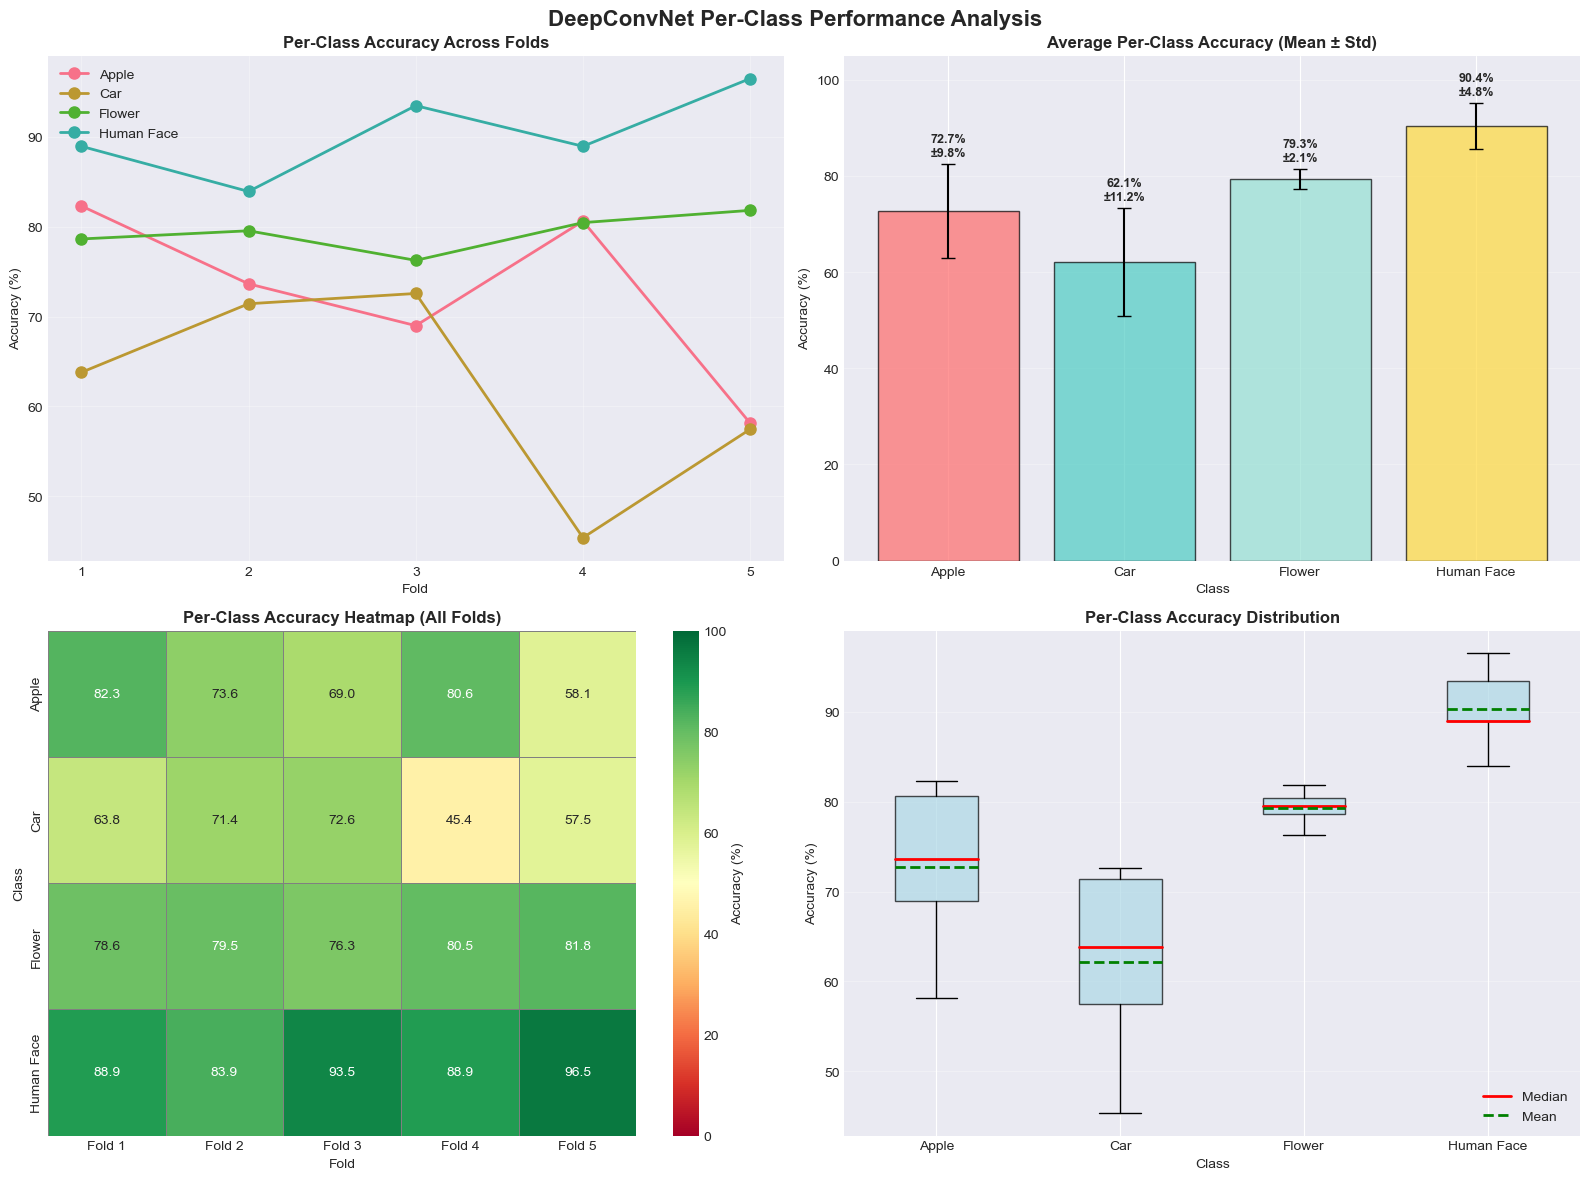

✅ Per-class accuracy visualization saved to: deepconvnet_per_class_accuracy.png


In [15]:
# Visualize per-class accuracy
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
fig.suptitle('DeepConvNet Per-Class Performance Analysis', fontsize=16, fontweight='bold')

# Plot 1: Per-class accuracy across folds
class_columns = ['Apple', 'Car', 'Flower', 'Human_Face']
class_display_names = ['Apple', 'Car', 'Flower', 'Human Face']

for i, (col, name) in enumerate(zip(class_columns, class_display_names)):
    axes[0, 0].plot(per_class_df['Fold'], per_class_df[col], 
                    marker='o', label=name, linewidth=2, markersize=8)

axes[0, 0].set_title('Per-Class Accuracy Across Folds', fontsize=12, fontweight='bold')
axes[0, 0].set_xlabel('Fold')
axes[0, 0].set_ylabel('Accuracy (%)')
axes[0, 0].legend()
axes[0, 0].grid(True, alpha=0.3)
axes[0, 0].set_xticks(per_class_df['Fold'])

# Plot 2: Average per-class accuracy (bar plot)
mean_accuracies = [per_class_df[col].mean() for col in class_columns]
std_accuracies = [per_class_df[col].std() for col in class_columns]

bars = axes[0, 1].bar(class_display_names, mean_accuracies, 
                      yerr=std_accuracies, capsize=5, 
                      color=['#FF6B6B', '#4ECDC4', '#95E1D3', '#FFD93D'],
                      edgecolor='black', alpha=0.7)

axes[0, 1].set_title('Average Per-Class Accuracy (Mean ± Std)', fontsize=12, fontweight='bold')
axes[0, 1].set_xlabel('Class')
axes[0, 1].set_ylabel('Accuracy (%)')
axes[0, 1].grid(True, alpha=0.3, axis='y')
axes[0, 1].set_ylim([0, 105])

# Add value labels on bars
for bar, mean, std in zip(bars, mean_accuracies, std_accuracies):
    height = bar.get_height()
    axes[0, 1].text(bar.get_x() + bar.get_width()/2., height + std + 1,
                   f'{mean:.1f}%\n±{std:.1f}%',
                   ha='center', va='bottom', fontsize=9, fontweight='bold')

# Plot 3: Heatmap of per-class accuracy across folds
heatmap_data = per_class_df[class_columns].T
sns.heatmap(heatmap_data, annot=True, fmt='.1f', cmap='RdYlGn', 
            xticklabels=[f'Fold {i}' for i in per_class_df['Fold']],
            yticklabels=class_display_names,
            ax=axes[1, 0], cbar_kws={'label': 'Accuracy (%)'},
            vmin=0, vmax=100, linewidths=0.5, linecolor='gray')

axes[1, 0].set_title('Per-Class Accuracy Heatmap (All Folds)', fontsize=12, fontweight='bold')
axes[1, 0].set_xlabel('Fold')
axes[1, 0].set_ylabel('Class')

# Plot 4: Box plot showing distribution
box_data = [per_class_df[col].values for col in class_columns]
bp = axes[1, 1].boxplot(box_data, labels=class_display_names, patch_artist=True,
                        showmeans=True, meanline=True,
                        boxprops=dict(facecolor='lightblue', alpha=0.7),
                        medianprops=dict(color='red', linewidth=2),
                        meanprops=dict(color='green', linewidth=2, linestyle='--'))

axes[1, 1].set_title('Per-Class Accuracy Distribution', fontsize=12, fontweight='bold')
axes[1, 1].set_xlabel('Class')
axes[1, 1].set_ylabel('Accuracy (%)')
axes[1, 1].grid(True, alpha=0.3, axis='y')
axes[1, 1].legend([bp['medians'][0], bp['means'][0]], 
                  ['Median', 'Mean'], loc='lower right')

plt.tight_layout()
plt.savefig('deepconvnet_per_class_accuracy.png', dpi=300, bbox_inches='tight')
plt.show()

print("✅ Per-class accuracy visualization saved to: deepconvnet_per_class_accuracy.png")

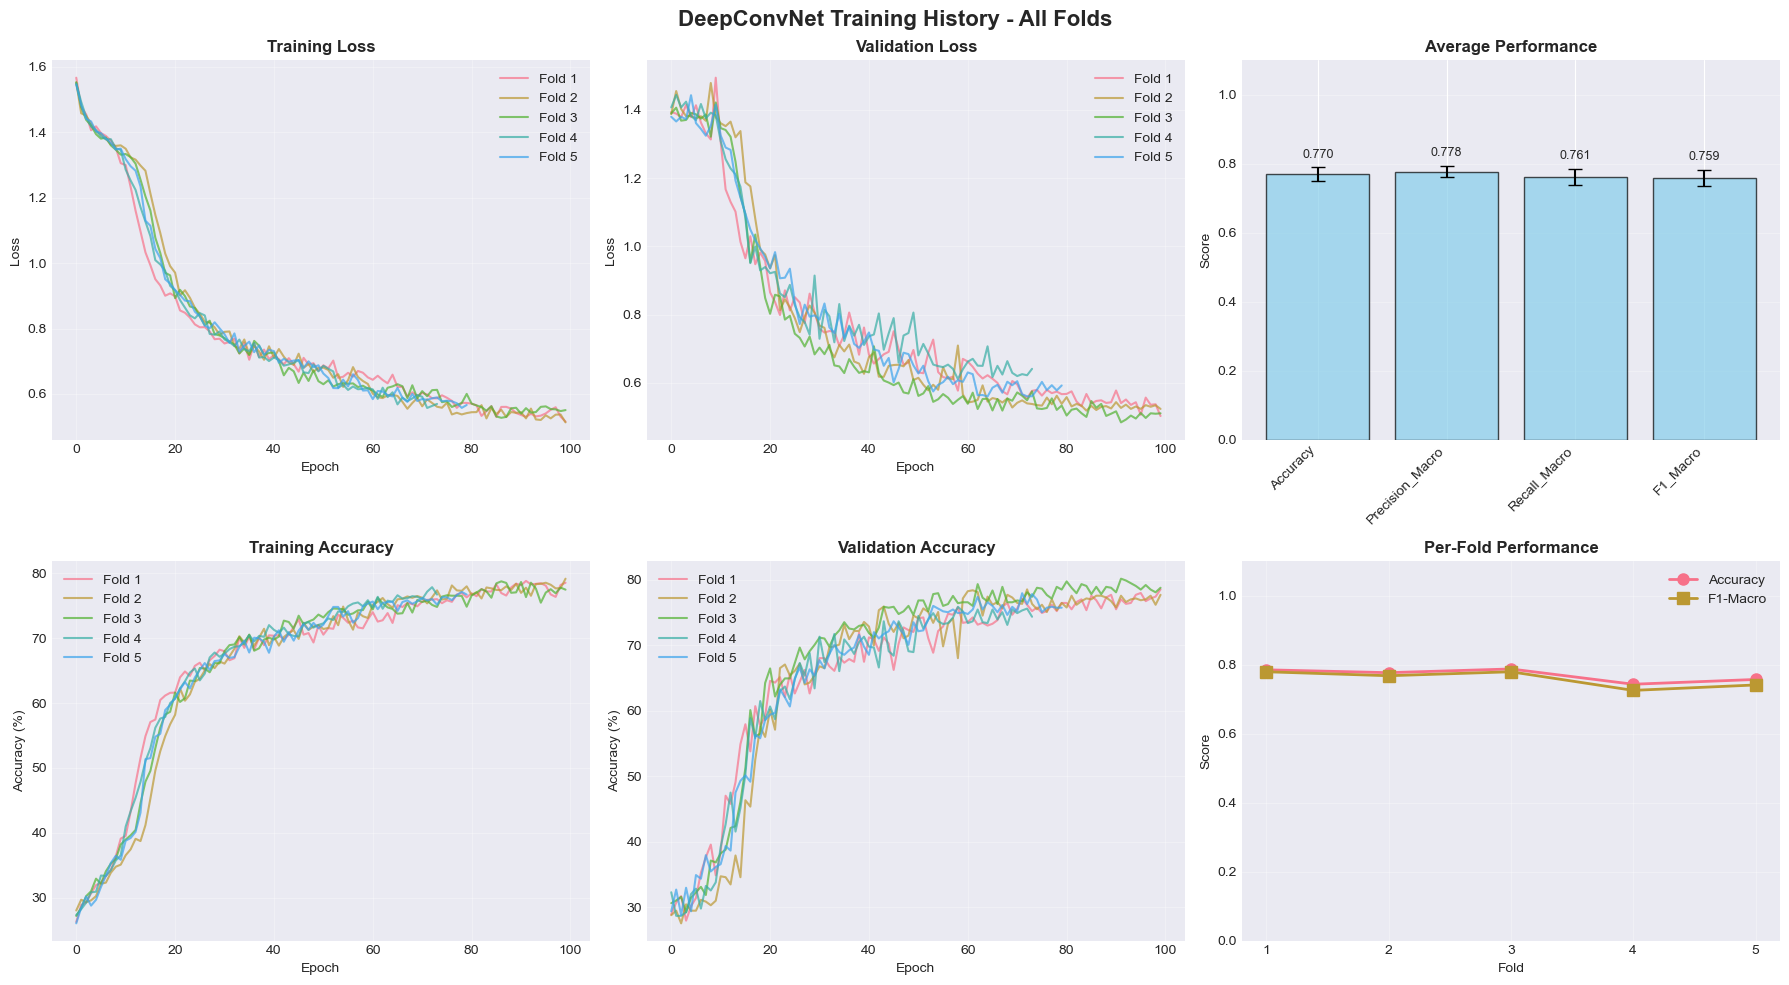

✅ Training history plot saved to: deepconvnet_training_history.png


In [11]:
# Plot training history for all folds
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
fig.suptitle('DeepConvNet Training History - All Folds', fontsize=16, fontweight='bold')

# Loss plots
for fold_idx, history in enumerate(training_histories):
    axes[0, 0].plot(history['train_loss'], label=f'Fold {fold_idx+1}', alpha=0.7)
    axes[0, 1].plot(history['test_loss'], label=f'Fold {fold_idx+1}', alpha=0.7)
    axes[1, 0].plot(history['train_acc'], label=f'Fold {fold_idx+1}', alpha=0.7)
    axes[1, 1].plot(history['test_acc'], label=f'Fold {fold_idx+1}', alpha=0.7)

axes[0, 0].set_title('Training Loss', fontsize=12, fontweight='bold')
axes[0, 0].set_xlabel('Epoch')
axes[0, 0].set_ylabel('Loss')
axes[0, 0].legend()
axes[0, 0].grid(True, alpha=0.3)

axes[0, 1].set_title('Validation Loss', fontsize=12, fontweight='bold')
axes[0, 1].set_xlabel('Epoch')
axes[0, 1].set_ylabel('Loss')
axes[0, 1].legend()
axes[0, 1].grid(True, alpha=0.3)

axes[1, 0].set_title('Training Accuracy', fontsize=12, fontweight='bold')
axes[1, 0].set_xlabel('Epoch')
axes[1, 0].set_ylabel('Accuracy (%)')
axes[1, 0].legend()
axes[1, 0].grid(True, alpha=0.3)

axes[1, 1].set_title('Validation Accuracy', fontsize=12, fontweight='bold')
axes[1, 1].set_xlabel('Epoch')
axes[1, 1].set_ylabel('Accuracy (%)')
axes[1, 1].legend()
axes[1, 1].grid(True, alpha=0.3)

# Performance summary bar plot
metrics = ['Accuracy', 'Precision_Macro', 'Recall_Macro', 'F1_Macro']
means = [summary_df[summary_df['Metric'] == m]['Mean'].values[0] for m in metrics]
stds = [summary_df[summary_df['Metric'] == m]['Std'].values[0] for m in metrics]

x = np.arange(len(metrics))
axes[0, 2].bar(x, means, yerr=stds, capsize=5, alpha=0.7, color='skyblue', edgecolor='black')
axes[0, 2].set_title('Average Performance', fontsize=12, fontweight='bold')
axes[0, 2].set_ylabel('Score')
axes[0, 2].set_xticks(x)
axes[0, 2].set_xticklabels(metrics, rotation=45, ha='right')
axes[0, 2].set_ylim([0, 1.1])
axes[0, 2].grid(True, alpha=0.3, axis='y')

# Add value labels on bars
for i, (m, s) in enumerate(zip(means, stds)):
    axes[0, 2].text(i, m + s + 0.02, f'{m:.3f}', ha='center', va='bottom', fontsize=9)

# Fold comparison
folds = results_df['Fold'].values
accuracies = results_df['Accuracy'].values
f1_scores = results_df['F1_Macro'].values

axes[1, 2].plot(folds, accuracies, marker='o', label='Accuracy', linewidth=2, markersize=8)
axes[1, 2].plot(folds, f1_scores, marker='s', label='F1-Macro', linewidth=2, markersize=8)
axes[1, 2].set_title('Per-Fold Performance', fontsize=12, fontweight='bold')
axes[1, 2].set_xlabel('Fold')
axes[1, 2].set_ylabel('Score')
axes[1, 2].set_xticks(folds)
axes[1, 2].legend()
axes[1, 2].grid(True, alpha=0.3)
axes[1, 2].set_ylim([0, 1.1])

plt.tight_layout()
plt.savefig('deepconvnet_training_history.png', dpi=300, bbox_inches='tight')
plt.show()

print("✅ Training history plot saved to: deepconvnet_training_history.png")

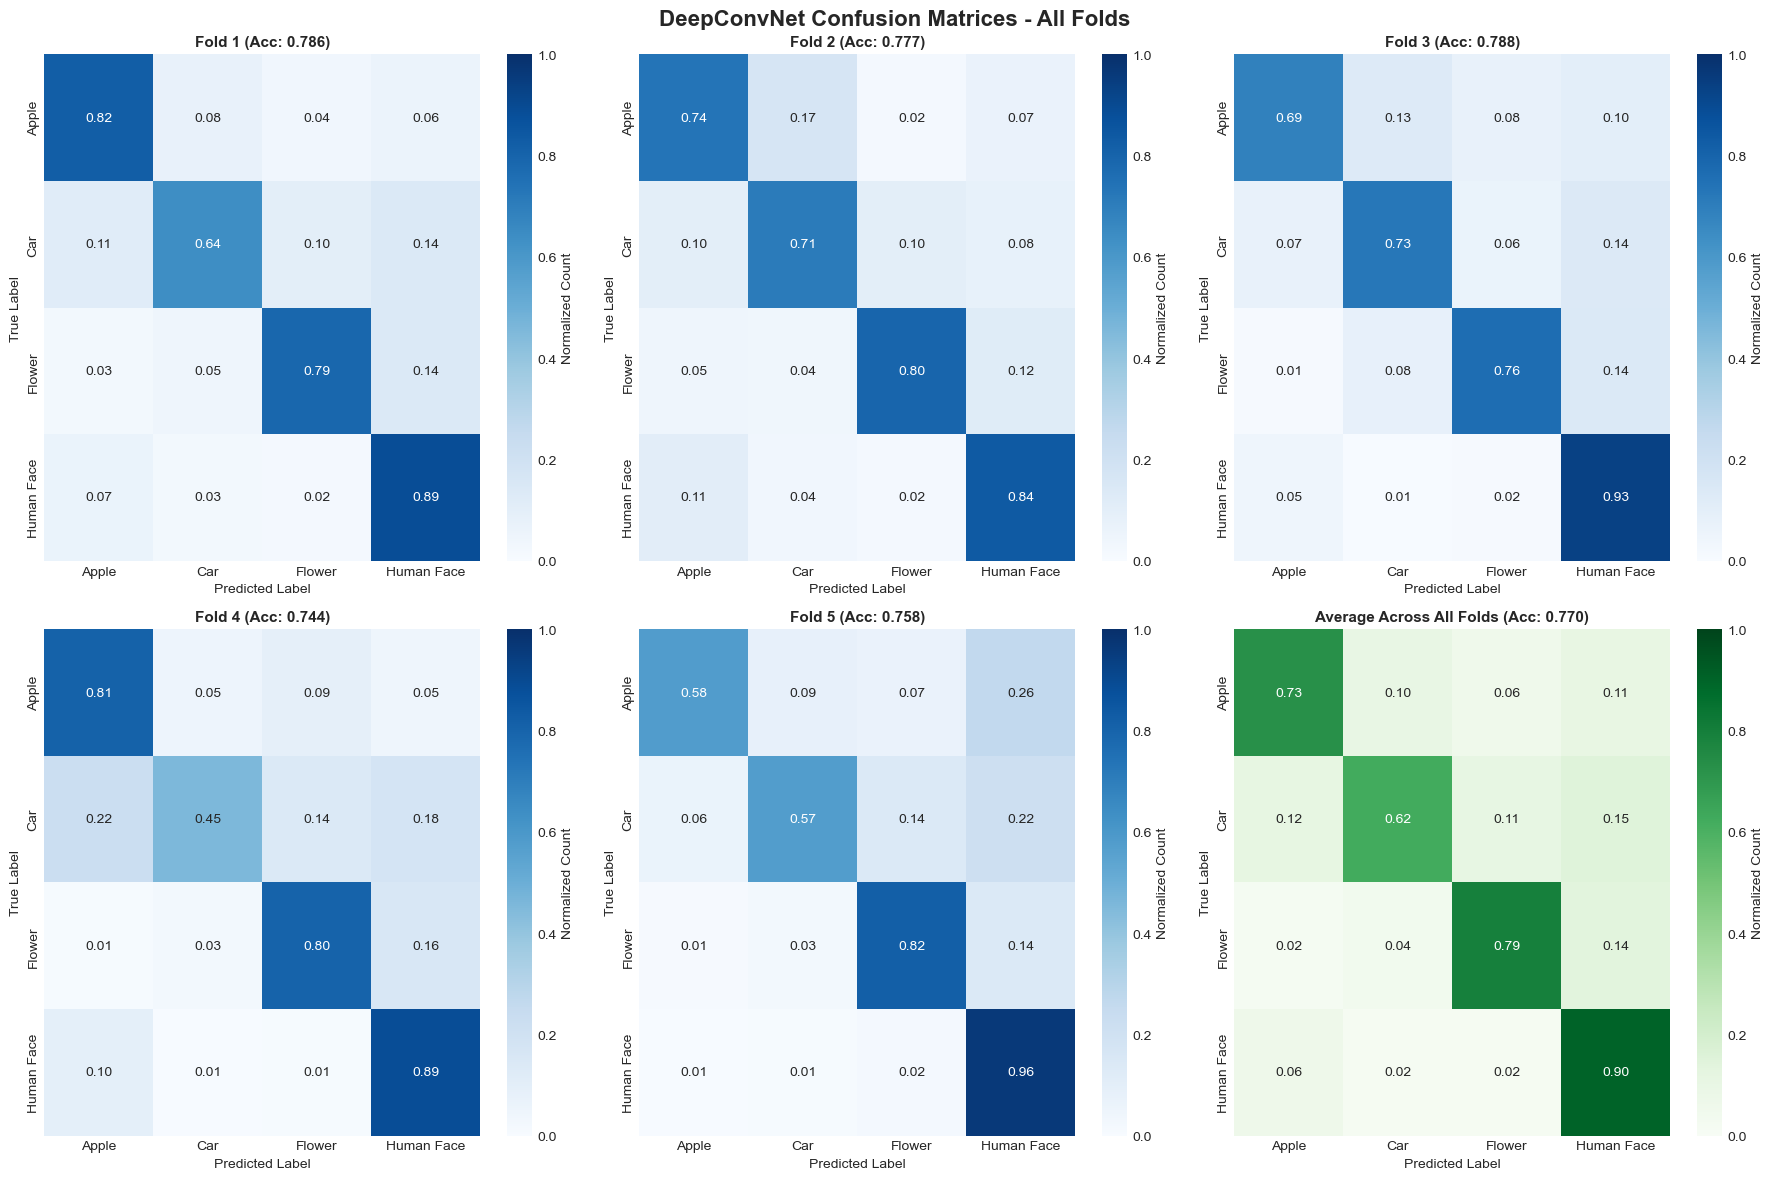

✅ Confusion matrices plot saved to: deepconvnet_confusion_matrices.png
✅ Confusion matrix data saved to: deepconvnet_confusion_matrix.csv


In [12]:
# Plot confusion matrices for all folds
fig, axes = plt.subplots(2, 3, figsize=(18, 12))
fig.suptitle('DeepConvNet Confusion Matrices - All Folds', fontsize=16, fontweight='bold')

for fold_idx, cm in enumerate(all_confusion_matrices):
    row = fold_idx // 3
    col = fold_idx % 3
    
    # Normalize confusion matrix
    cm_normalized = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]
    
    # Plot
    sns.heatmap(cm_normalized, annot=True, fmt='.2f', cmap='Blues', 
                xticklabels=class_names, yticklabels=class_names,
                ax=axes[row, col], cbar_kws={'label': 'Normalized Count'},
                vmin=0, vmax=1)
    
    axes[row, col].set_title(f'Fold {fold_idx + 1} (Acc: {results_df.iloc[fold_idx]["Accuracy"]:.3f})',
                             fontsize=11, fontweight='bold')
    axes[row, col].set_xlabel('Predicted Label', fontsize=10)
    axes[row, col].set_ylabel('True Label', fontsize=10)

# Calculate and plot average confusion matrix
avg_cm = np.mean(all_confusion_matrices, axis=0)
avg_cm_normalized = avg_cm / avg_cm.sum(axis=1)[:, np.newaxis]

sns.heatmap(avg_cm_normalized, annot=True, fmt='.2f', cmap='Greens',
            xticklabels=class_names, yticklabels=class_names,
            ax=axes[1, 2], cbar_kws={'label': 'Normalized Count'},
            vmin=0, vmax=1)

axes[1, 2].set_title(f'Average Across All Folds (Acc: {summary_df[summary_df["Metric"]=="Accuracy"]["Mean"].values[0]:.3f})',
                     fontsize=11, fontweight='bold')
axes[1, 2].set_xlabel('Predicted Label', fontsize=10)
axes[1, 2].set_ylabel('True Label', fontsize=10)

plt.tight_layout()
plt.savefig('deepconvnet_confusion_matrices.png', dpi=300, bbox_inches='tight')
plt.show()

print("✅ Confusion matrices plot saved to: deepconvnet_confusion_matrices.png")

# Save confusion matrix data
cm_data = []
for fold_idx, cm in enumerate(all_confusion_matrices):
    for i, true_class in enumerate(class_names):
        for j, pred_class in enumerate(class_names):
            cm_data.append({
                'Fold': fold_idx + 1,
                'True_Class': true_class,
                'Predicted_Class': pred_class,
                'Count': cm[i, j]
            })

cm_df = pd.DataFrame(cm_data)
cm_df.to_csv('deepconvnet_confusion_matrix.csv', index=False)
print("✅ Confusion matrix data saved to: deepconvnet_confusion_matrix.csv")

In [13]:
print("\n" + "="*80)
print("DeepConvNet TRAINING COMPLETED - FINAL SUMMARY")
print("="*80)
print(f"\nModel: DeepConvNet (Deep Convolutional Network)")
print(f"Architecture Components:")
print(f"  - Block 1: Temporal Conv (1, 10) + Spatial Conv (14, 1) + MaxPool + Dropout")
print(f"  - Block 2: Conv (1, 10) + MaxPool + Dropout")
print(f"  - Block 3: Conv (1, 10) + MaxPool + Dropout")
print(f"  - Block 4: Conv (1, 10) + MaxPool + Dropout")
print(f"  - Dense Classification Layer")
print(f"\nModel Parameters: {sum(p.numel() for p in DeepConvNet(nb_classes=4, Chans=14, Samples=128).parameters()):,}")
print(f"\nDataset:")
print(f"  - Total Samples: 3612")
print(f"  - Classes: 4 (Apple, Car, Flower, Human Face)")
print(f"  - Input Shape: (1, 14, 128) - [Channels, EEG Channels, Time Points]")
print(f"  - Features: 14 channels × 128 time points = 1792")
print(f"\nTraining Configuration:")
print(f"  - Cross-Validation: 5-Fold Stratified")
print(f"  - Batch Size: {BATCH_SIZE}")
print(f"  - Learning Rate: {LEARNING_RATE}")
print(f"  - Optimizer: Adam")
print(f"  - Loss Function: CrossEntropyLoss")
print(f"  - Dropout Rate: {DROPOUT_RATE}")
print(f"  - Early Stopping Patience: {PATIENCE}")
print(f"  - LR Scheduler: ReduceLROnPlateau (factor=0.5, patience=5)")
print(f"  - Device: {device}")
print(f"\n" + "-"*80)
print("PERFORMANCE METRICS (Mean ± Std):")
print("-"*80)
for _, row in summary_df.iterrows():
    print(f"{row['Metric']:20s}: {row['Mean']:.4f} ± {row['Std']:.4f}")

print("\n" + "-"*80)
print("PER-FOLD ACCURACY:")
print("-"*80)
for _, row in results_df.iterrows():
    print(f"Fold {int(row['Fold'])}: {row['Accuracy']:.4f} (Best Epoch: {int(row['Best_Epoch'])})")

print("\n" + "="*80)
print("OUTPUT FILES GENERATED:")
print("="*80)
print("  ✅ deepconvnet_results_summary.csv        - Summary statistics")
print("  ✅ deepconvnet_fold_details.csv           - Detailed per-fold results")
print("  ✅ deepconvnet_confusion_matrix.csv       - Confusion matrix data")
print("  ✅ deepconvnet_training_history.png       - Training history visualization")
print("  ✅ deepconvnet_confusion_matrices.png     - Confusion matrices visualization")
print("="*80)

print("\n🎉 DeepConvNet training pipeline completed successfully!")
print("="*80)


DeepConvNet TRAINING COMPLETED - FINAL SUMMARY

Model: DeepConvNet (Deep Convolutional Network)
Architecture Components:
  - Block 1: Temporal Conv (1, 10) + Spatial Conv (14, 1) + MaxPool + Dropout
  - Block 2: Conv (1, 10) + MaxPool + Dropout
  - Block 3: Conv (1, 10) + MaxPool + Dropout
  - Block 4: Conv (1, 10) + MaxPool + Dropout
  - Dense Classification Layer

Model Parameters: 144,479

Dataset:
  - Total Samples: 3612
  - Classes: 4 (Apple, Car, Flower, Human Face)
  - Input Shape: (1, 14, 128) - [Channels, EEG Channels, Time Points]
  - Features: 14 channels × 128 time points = 1792

Training Configuration:
  - Cross-Validation: 5-Fold Stratified
  - Batch Size: 32
  - Learning Rate: 0.001
  - Optimizer: Adam
  - Loss Function: CrossEntropyLoss
  - Dropout Rate: 0.5
  - Early Stopping Patience: 15
  - LR Scheduler: ReduceLROnPlateau (factor=0.5, patience=5)
  - Device: cuda

--------------------------------------------------------------------------------
PERFORMANCE METRICS (M